# Deep Gaussian Process

Import library

In [96]:
import numpy as np
from matplotlib import pyplot as plt

## Gaussian Process

In [97]:
def squared_exponential(x1, x2, length_scale, sigma):
    return sigma**2 * np.exp((-(x1-x2)**2)/(2*length_scale**2))

In [98]:
x_try1 = squared_exponential(np.array([5]), np.array([5]), 1, 1)
print(x_try1)
x_try2 = squared_exponential(np.array([0.0]), np.array([100.0]), 1, 1)
print(x_try2)

[1.]
[0.]


In [99]:
x_train = np.array([0, 1, 2, 3, 4])
y_train = np.array([15, 8, 9, 20, 12])

In [100]:
def R(x1, x2, nugget, length_scale=1, sigma=1):
    n = len(x1)
    m = len(x2)
    R_matrix = np.zeros((n, m))
    I = np.zeros((n, m))
    for i in range(n):
        for j in range(m):
            I[i,j] = 1 if i==j else 0
    for i in range(n):
        for j in range(m):
            R_matrix[i][j] = squared_exponential(x1[i], x2[j], length_scale, sigma)
    return R_matrix + nugget * I

In [101]:
R_try1 = R(np.array([1.0,2.0,4.0]), np.array([1.0,2.0,4.0]), nugget=0, length_scale=1, sigma=1)
print(R_try1)
R_try2 = R(np.array([2.0,2.0,5.0]), np.array([2.0,2.0,5.0]), nugget=0.1, length_scale=1, sigma=1)
print(R_try2)
R_try3 = R(np.array([1.0,2.0,3.0,4.0,5.0]), np.array([10.0,20.0]), nugget=0, length_scale=1, sigma=1)
print(R_try3)

[[1.         0.60653066 0.011109  ]
 [0.60653066 1.         0.13533528]
 [0.011109   0.13533528 1.        ]]
[[1.1      1.       0.011109]
 [1.       1.1      0.011109]
 [0.011109 0.011109 1.1     ]]
[[2.57675711e-18 4.07235863e-79]
 [1.26641655e-14 4.40853133e-71]
 [2.28973485e-11 1.75568810e-63]
 [1.52299797e-08 2.57220937e-56]
 [3.72665317e-06 1.38634329e-49]]


In [102]:
def gp_predict(x_new, x_train, y_train, length_scale, R_inv, sigma = 1, nugget = 1):
    r_x0 = np.array([squared_exponential(x_new, x_i, length_scale, sigma) for x_i in x_train])
    mean = r_x0.T @ R_inv @ y_train
    variance = sigma**2 * (1 + nugget - r_x0.T @ R_inv @ r_x0)
    return mean, variance

In [103]:
R_inv = np.linalg.inv(R(x_train, x_train, nugget=0.1, length_scale=1, sigma=1))
mean, variance = gp_predict(2, x_train, y_train, length_scale=1, R_inv=R_inv, sigma=1, nugget=0.1)
print('Mean:', mean, 'Variance:', variance)

Mean: 9.459319638133973 Variance: 0.1769139208199808


In [104]:
R_inv = np.linalg.inv(R(x_train, x_train, nugget=0.1, length_scale=1, sigma=1))
mean, variance = gp_predict(2, x_train, y_train, length_scale=1, R_inv=R_inv, sigma=1, nugget=1)
print('Mean:', mean, 'Variance:', variance)

Mean: 9.459319638133973 Variance: 1.0769139208199807


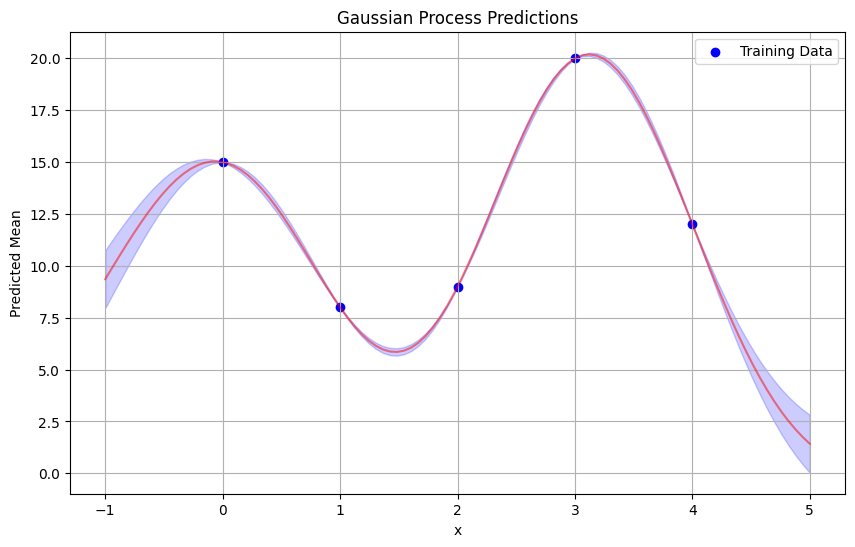

In [105]:
plt.figure(figsize=(10, 6))
plt.scatter(x_train, y_train, color='blue', label='Training Data')
x_new = np.linspace(-1, 5, 100)
mean_list = []
variance_list = []
R_inv = np.linalg.inv(R(x_train, x_train, nugget=10e-5, length_scale=1, sigma=1))
for x in x_new:
    mean, variance = gp_predict(x, x_train, y_train, length_scale=1, R_inv=R_inv, sigma=1, nugget=10e-5)
    mean_list.append(mean)
    variance_list.append(variance)
plt.plot(x_new, np.array(mean_list), color='red', alpha=0.5)
plt.fill_between(x_new, np.array(mean_list) - 1.96 * np.sqrt(np.array(variance_list)), np.array(mean_list) + 1.96 * np.sqrt(np.array(variance_list)), color='blue', alpha=0.2)
plt.title('Gaussian Process Predictions')
plt.xlabel('x')
plt.ylabel('Predicted Mean')
plt.legend()
plt.grid()
plt.show()

## Linked Gaussian Process

In [106]:
x_train = np.linspace(0, 10, 8)
w_train = np.sin(x_train) * 5 + np.random.normal(0, 0.3, size=8)
y_train = w_train**2 + np.random.normal(0, 0.5, size=8)
print('x_train:', x_train)
print('w_train:', w_train)
print('y_train:', y_train)      

x_train: [ 0.          1.42857143  2.85714286  4.28571429  5.71428571  7.14285714
  8.57142857 10.        ]
w_train: [-0.45778531  4.64150031  1.37186322 -4.04625374 -2.8195796   3.46122332
  3.66362954 -2.67489377]
y_train: [-0.17056307 21.81941418  1.05305778 16.98577027  7.61515109 12.29852922
 13.64708322  7.66679007]


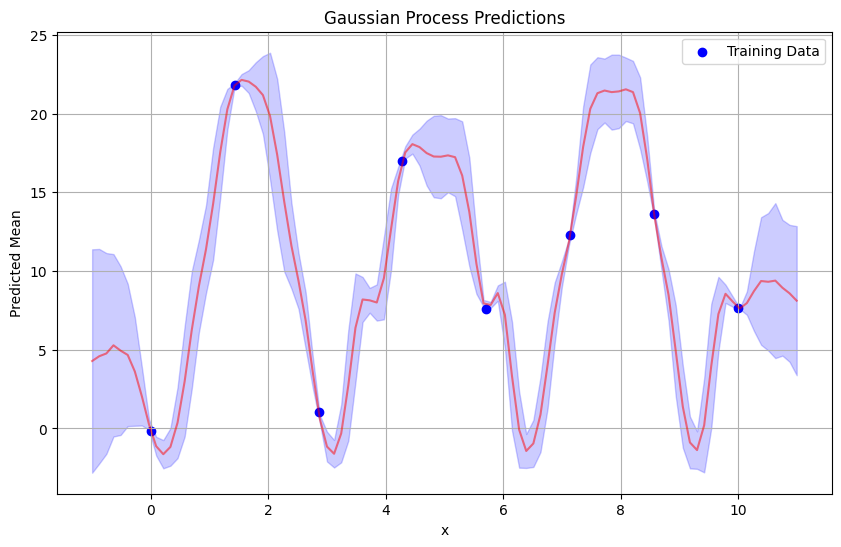

In [107]:
plt.figure(figsize=(10, 6))
plt.scatter(x_train, y_train, color='blue', label='Training Data')
x_new = np.linspace(-1, 11, 100)
mean1_list = []
variance1_list = []
R_inv_1 = np.linalg.inv(R(x_train, x_train, nugget=10e-5, length_scale=1, sigma=1))
for x in x_new:
    mean, variance = gp_predict(x, x_train, w_train, length_scale=1, R_inv=R_inv_1, sigma=1, nugget=10e-5)
    mean1_list.append(mean)
    variance1_list.append(variance)
R_inv_2 = np.linalg.inv(R(w_train, w_train, nugget=10e-5, length_scale=1, sigma=1))
mean2_list = []
variance2_list = []
# mean2_naive_list = []
# variance2_naive_list = []
# for m_new in mean1_list:
#     mean, variance = gp_predict(m_new, w_train, y_train, length_scale=1, R_inv=R_inv_2, sigma=1, nugget=10e-5)
#     mean2_naive_list.append(mean)
#     variance2_naive_list.append(variance)
for m, v in zip(mean1_list, variance1_list):
    w_new = np.random.normal(m, np.sqrt(v), size=1000)
    mean2_loop_list = []
    variance2_loop_list = []
    for w in w_new:
        mean, variance = gp_predict(w, w_train, y_train, length_scale=1, R_inv=R_inv_2, sigma=1, nugget=10e-5)
        mean2_loop_list.append(mean)
        variance2_loop_list.append(variance)
    mean2_list.append(np.mean(mean2_loop_list))
    mean_sq_plus_var = np.array(mean2_loop_list)**2 + np.array(variance2_loop_list)
    term1 = np.mean(mean_sq_plus_var)
    term2 = np.mean(mean2_loop_list)**2
    variance2_list.append(term1 - term2)

plt.plot(x_new, np.array(mean2_list), color='red', alpha=0.5)
plt.fill_between(x_new, np.array(mean2_list) - 1.96 * np.sqrt(np.array(variance2_list)), np.array(mean2_list) + 1.96 * np.sqrt(np.array(variance2_list)), color='blue', alpha=0.2)
# plt.plot(x_new, np.array(mean2_naive_list), color='orange', alpha=0.5)
# plt.fill_between(x_new, np.array(mean2_naive_list) - 1.96 * np.sqrt(np.array(variance2_naive_list)), np.array(mean2_naive_list) + 1.96 * np.sqrt(np.array(variance2_naive_list)), color='green', alpha=0.2)
plt.title('Gaussian Process Predictions')
plt.xlabel('x')
plt.ylabel('Predicted Mean')
plt.legend()
plt.grid()
plt.show()

## Deep Gaussian Process

In [150]:
def squared_exponential(x1, x2, length_scale, sigma):
    return np.exp(-((x1 - x2) ** 2) / (2 * length_scale ** 2))

def R(x1, x2, nugget, length_scale=1.0, sigma=1.0):
    n, m = len(x1), len(x2)
    R_matrix = np.zeros((n, m))
    I = np.eye(n, m)
    for i in range(n):
        for j in range(m):
            R_matrix[i, j] = squared_exponential(x1[i], x2[j], length_scale, sigma)
    return R_matrix + nugget * I

def gp_predict(x_new, x_train, y_train, length_scale, R_inv, sigma=1.0, nugget=1.0):
    r_x0 = np.array([squared_exponential(x_new, x_i, length_scale, sigma) for x_i in x_train])
    mean = r_x0.T @ R_inv @ y_train
    variance = sigma ** 2 * (1 + nugget - r_x0.T @ R_inv @ r_x0)
    variance = max(variance, 1e-8)  # guard against tiny negative numbers from floating point error
    return mean, variance

### M-step

In [166]:
def log_marginal_likelihood(x_train, y_train, length_scale, sigma, nugget):
    n = len(x_train)
    Rmat = R(x_train, x_train, nugget=nugget, length_scale=length_scale, sigma=sigma)
    try:
        R_inv = np.linalg.inv(Rmat)
        sign, logdet = np.linalg.slogdet(Rmat)
        if sign <= 0:
            return -np.inf
    except np.linalg.LinAlgError:
        return -np.inf
    term1 = -0.5 * y_train.T @ R_inv @ y_train
    term2 = -0.5 * logdet
    term3 = -0.5 * n * np.log(2 * np.pi)
    return term1 + term2 + term3

def fit_hyperparameters(x_train, y_train, nugget,
                         length_scale_grid=None, sigma_grid=None):
    """Simple grid search over (length_scale, sigma) maximizing log marginal likelihood."""
    if length_scale_grid is None:
        data_span = max(np.ptp(x_train), 1e-3)
        length_scale_grid = np.linspace(max(1.0, data_span / 3), data_span * 2, 25)
    if sigma_grid is None:
        data_std = max(np.std(y_train), 1e-3)
        sigma_grid = np.linspace(0.5 * data_std, 3 * data_std, 15)
 
    best_score = -np.inf
    best_params = (length_scale_grid[0], sigma_grid[0])
    for ls in length_scale_grid:
        for sg in sigma_grid:
            score = log_marginal_likelihood(x_train, y_train, ls, sg, nugget)
            if score > best_score:
                best_score = score
                best_params = (ls, sg)
    return best_params  # (length_scale, sigma)

### I-step

In [167]:
def candidate_log_likelihood(w_candidate, y_actual, w_others, y_others, R_inv_2, ls2, sg2, nugget):
    mean, variance = gp_predict(w_candidate, w_others, y_others, length_scale=ls2,
                                 R_inv=R_inv_2, sigma=sg2, nugget=nugget)
    return -0.5 * np.log(2 * np.pi * variance) - 0.5 * ((y_actual - mean) ** 2 / variance)
 
 
def prior_log_likelihood(w_candidate, x_actual, x_others, w_others, R_inv_1, ls1, sg1, nugget):
    mean, variance = gp_predict(x_actual, x_others, w_others, length_scale=ls1,
                                 R_inv=R_inv_1, sigma=sg1, nugget=nugget)
    return -0.5 * np.log(2 * np.pi * variance) - 0.5 * ((w_candidate - mean) ** 2 / variance)
 
 
def total_log_posterior(w_candidate, idx, x_train, w_guess, y_train,
                         R_inv_1, R_inv_2, ls1, sg1, ls2, sg2, nugget):
    mask = np.arange(len(w_guess)) != idx
    prior_ll = prior_log_likelihood(w_candidate, x_train[idx], x_train[mask], w_guess[mask],
                                     R_inv_1, ls1, sg1, nugget)
    data_ll = candidate_log_likelihood(w_candidate, y_train[idx], w_guess[mask], y_train[mask],
                                        R_inv_2, ls2, sg2, nugget)
    return prior_ll + data_ll
 
 
def impute_one_point(idx, x_train, w_guess, y_train, R_inv_1, R_inv_2,
                      ls1, sg1, ls2, sg2, nugget, search_range, sample=False):
    scores = np.array([
        total_log_posterior(w_c, idx, x_train, w_guess, y_train, R_inv_1, R_inv_2,
                             ls1, sg1, ls2, sg2, nugget)
        for w_c in search_range
    ])
    if sample:
        # soft-max the scores into a probability distribution and sample from it
        # (an approximation of ESS: instead of just taking the best guess, draw a
        # random sample so uncertainty about w is reflected, not just a point estimate)
        scores = scores - np.max(scores)  # for numerical stability
        probs = np.exp(scores)
        probs /= probs.sum()
        return np.random.choice(search_range, p=probs)
    else:
        return search_range[np.argmax(scores)]
 

### ESS

In [168]:

def ess_sample_one_point(w_current, prior_mean, prior_var, log_lik_fn, max_shrinks=100):
    """
    Draw one sample from pi(w) propto L(w) * N(w; prior_mean, prior_var)
    using Elliptical Slice Sampling -- no tuning, no rejection-forever risk.
 
    log_lik_fn: a function taking a candidate w and returning log L(w)
                (here: the GP2 "does this w explain the observed y" piece,
                 Eq. 8's data-likelihood term, NOT including the prior piece --
                 the prior piece is handled by the ellipse itself).
    """
    sigma = np.sqrt(prior_var)
 
    # Step 1-2: center current point, draw the auxiliary "partner" from the prior shape
    f = w_current - prior_mean
    nu = np.random.normal(0, sigma)
 
    # Step 3: log-likelihood threshold
    log_y = log_lik_fn(w_current) + np.log(np.random.uniform(0, 1))
 
    # Step 4: initial angle and bracket
    theta = np.random.uniform(0, 2 * np.pi)
    theta_min, theta_max = theta - 2 * np.pi, theta
 
    for _ in range(max_shrinks):
        # Step 5: propose a point on the ellipse
        f_prime = f * np.cos(theta) + nu * np.sin(theta)
        w_prime = f_prime + prior_mean
 
        # Step 6: accept/reject
        if log_lik_fn(w_prime) > log_y:
            return w_prime
 
        # Step 7: shrink the bracket
        if theta < 0:
            theta_min = theta
        else:
            theta_max = theta
        theta = np.random.uniform(theta_min, theta_max)
 
    # Should essentially never happen, but guard against infinite loops
    return w_current
 
 
def impute_one_point_ess(idx, x_train, w_guess, y_train, R_inv_1, R_inv_2,
                          ls1, sg1, ls2, sg2, nugget):
    """
    True ESS version of impute_one_point. The "prior" (Gaussian piece) comes
    from GP1 (the layer below, Eq. 8's N(mu,Sigma) term); the "likelihood"
    (non-Gaussian piece) comes from GP2 (the layer above, Eq. 8's L(w) term).
    """
    mask = np.arange(len(w_guess)) != idx
    prior_mean, prior_var = gp_predict(x_train[idx], x_train[mask], w_guess[mask],
                                        length_scale=ls1, R_inv=R_inv_1, sigma=sg1, nugget=nugget)
 
    def log_lik_fn(w_candidate):
        return candidate_log_likelihood(w_candidate, y_train[idx], w_guess[mask], y_train[mask],
                                         R_inv_2, ls2, sg2, nugget)
 
    return ess_sample_one_point(w_guess[idx], prior_mean, prior_var, log_lik_fn)
 
 

### SEM loop

In [169]:

def run_sem(x_train, y_train, w_train_true=None, n_sweeps=25, nugget=0.05,
            search_range=None, sample=False, refit_every=1, verbose=True,
            use_ess=False):
    n = len(x_train)
    if search_range is None:
        span = max(np.sqrt(np.abs(y_train)).max() * 1.5, 1.0)
        search_range = np.linspace(-span, span, 300)
 
    # initialize w_guess with the right MAGNITUDE (from y_train) but random sign --
    # this directly tackles the sign-ambiguity issue from tonight's y = w^2 example
    w_guess = np.sqrt(np.abs(y_train)) * np.random.choice([-1, 1], size=n)
 
    # initial (bad) hyperparameters, will be refit in the M-step
    ls1, sg1 = 1.0, 1.0
    ls2, sg2 = 1.0, 1.0
 
    history = {"err_signed": [], "err_abs": [], "w_guess": []}
 
    for sweep in range(n_sweeps):
        # --- I-step: one full Gibbs sweep over all points ---
        for idx in range(n):
            mask = np.arange(n) != idx
            R_inv_1 = np.linalg.inv(R(x_train[mask], x_train[mask], nugget=nugget,
                                       length_scale=ls1, sigma=sg1))
            R_inv_2 = np.linalg.inv(R(w_guess[mask], w_guess[mask], nugget=nugget,
                                       length_scale=ls2, sigma=sg2))
            if use_ess:
                w_guess[idx] = impute_one_point_ess(idx, x_train, w_guess, y_train, R_inv_1, R_inv_2,
                                                     ls1, sg1, ls2, sg2, nugget)
            else:
                w_guess[idx] = impute_one_point(idx, x_train, w_guess, y_train, R_inv_1, R_inv_2,
                                                 ls1, sg1, ls2, sg2, nugget, search_range, sample=sample)
 
        # --- M-step: refit hyperparameters on the current imputed w_guess ---
        if sweep % refit_every == 0:
            ls1, sg1 = fit_hyperparameters(x_train, w_guess, nugget)
            ls2, sg2 = fit_hyperparameters(w_guess, y_train, nugget)
 
        if w_train_true is not None:
            err_signed = np.mean(np.abs(w_guess - w_train_true))
            err_abs = np.mean(np.abs(np.abs(w_guess) - np.abs(w_train_true)))
            history["err_signed"].append(err_signed)
            history["err_abs"].append(err_abs)
            history["w_guess"].append(w_guess.copy())
            if verbose:
                print(f"sweep {sweep+1:2d} | ls1={ls1:5.2f} sg1={sg1:5.2f} "
                      f"ls2={ls2:5.2f} sg2={sg2:5.2f} | signed_err={err_signed:.3f} "
                      f"| |w|_err={err_abs:.3f}")
 
    return w_guess, (ls1, sg1, ls2, sg2), history
 
 

Ground truth w: [-0.11  4.87  1.71 -4.54 -2.74  4.02  4.02 -2.54]

sweep  1 | ls1= 3.33 sg1= 1.41 ls2= 3.14 sg2= 3.97 | signed_err=3.849 | |w|_err=0.168
sweep  2 | ls1= 3.33 sg1= 1.36 ls2= 3.00 sg2= 3.97 | signed_err=3.833 | |w|_err=0.243
sweep  3 | ls1= 3.33 sg1= 2.73 ls2= 5.43 sg2= 3.97 | signed_err=5.303 | |w|_err=1.631
sweep  4 | ls1= 3.33 sg1= 2.73 ls2= 5.51 sg2= 3.97 | signed_err=5.435 | |w|_err=1.855
sweep  5 | ls1= 3.33 sg1= 2.75 ls2= 5.47 sg2= 3.97 | signed_err=5.432 | |w|_err=1.847
sweep  6 | ls1= 3.33 sg1= 2.80 ls2= 5.52 sg2= 3.97 | signed_err=5.589 | |w|_err=2.022
sweep  7 | ls1= 3.33 sg1= 2.81 ls2= 5.49 sg2= 3.97 | signed_err=5.585 | |w|_err=2.065
sweep  8 | ls1= 3.33 sg1= 2.80 ls2= 5.49 sg2= 3.97 | signed_err=5.536 | |w|_err=2.009
sweep  9 | ls1= 3.33 sg1= 2.82 ls2= 5.54 sg2= 3.97 | signed_err=5.502 | |w|_err=2.035
sweep 10 | ls1= 3.33 sg1= 2.84 ls2= 5.57 sg2= 3.97 | signed_err=5.556 | |w|_err=2.103
sweep 11 | ls1= 3.33 sg1= 2.83 ls2= 5.60 sg2= 3.97 | signed_err=5.577 | |

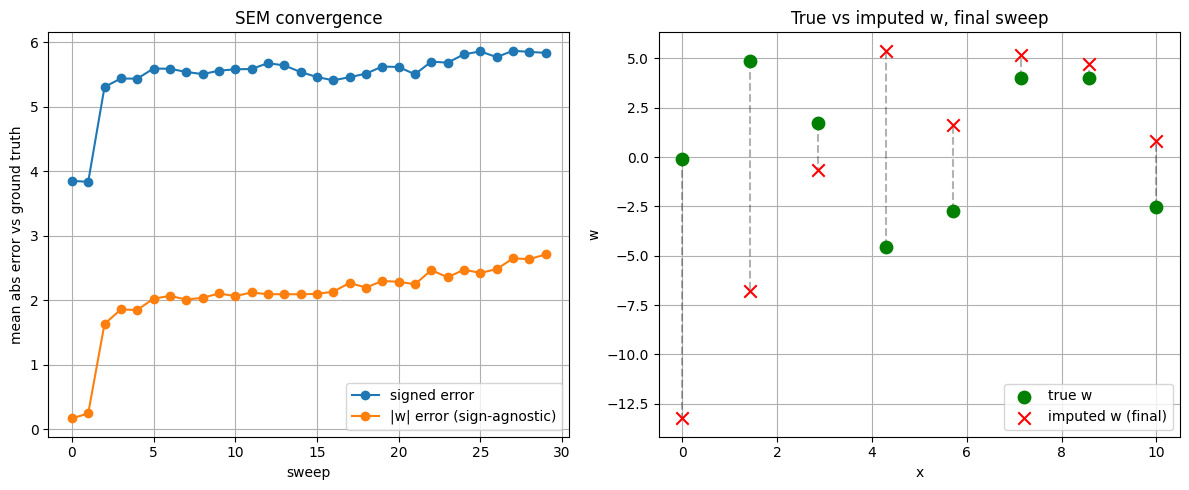

In [170]:

if __name__ == "__main__":
    # --- toy problem, same as tonight: X -> W -> Y, with W hidden ---
    x_train = np.linspace(0, 10, 8)
    w_train_true = np.sin(x_train) * 5 + np.random.normal(0, 0.3, size=8)
    y_train = w_train_true ** 2 + np.random.normal(0, 0.5, size=8)
 
    print("Ground truth w:", np.round(w_train_true, 2))
    print()
 
    w_final, hypers, history = run_sem(
        x_train, y_train, w_train_true=w_train_true,
        n_sweeps=30, nugget=0.05, sample=False, use_ess=True
    )
 
    print()
    print("Final w_guess:  ", np.round(w_final, 2))
    print("Ground truth:   ", np.round(w_train_true, 2))
    print("Final hyperparameters (ls1, sg1, ls2, sg2):", np.round(hypers, 2))
 
    # --- plot convergence ---
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].plot(history["err_signed"], marker='o', label="signed error")
    axes[0].plot(history["err_abs"], marker='o', label="|w| error (sign-agnostic)")
    axes[0].set_xlabel("sweep")
    axes[0].set_ylabel("mean abs error vs ground truth")
    axes[0].set_title("SEM convergence")
    axes[0].legend()
    axes[0].grid(True)
 
    axes[1].scatter(x_train, w_train_true, color='green', label='true w', s=80, zorder=3)
    axes[1].scatter(x_train, w_final, color='red', marker='x', label='imputed w (final)', s=80, zorder=3)
    for i in range(len(x_train)):
        axes[1].plot([x_train[i], x_train[i]], [w_train_true[i], w_final[i]], 'k--', alpha=0.3)
    axes[1].set_xlabel("x")
    axes[1].set_ylabel("w")
    axes[1].set_title("True vs imputed w, final sweep")
    axes[1].legend()
    axes[1].grid(True)
 
    plt.tight_layout()

In [171]:

def dgp_predict_at_point(x0, x_train, y_train, w_final, ls1, sg1, ls2, sg2, nugget,
                          n_imputations=15, mc_samples=150, ess_sweeps_between=3):
    """
    Predict y at a new input x0 from the trained DGP, combining TWO sources of
    uncertainty into one final (mean, variance) via Eq. (6):
      1. Imputation uncertainty -- we don't know exactly what w was at the
         training points, so we draw several fresh posterior imputations
         (advancing the ESS/Gibbs chain a few more sweeps each time).
      2. Propagation uncertainty -- within each imputation, GP1's prediction
         at x0 is itself uncertain, so (as in the linked-GP Stage J) we sample
         many plausible w0 values and push each through GP2.
    All of the resulting (mean, variance) pairs -- across both imputations and
    MC draws -- are combined in one flat application of Eq. (6).
    """
    all_means, all_vars = [], []
    w_current = w_final.copy()
    n = len(w_current)
 
    for _ in range(n_imputations):
        # advance the chain a few sweeps for a fresh-ish posterior draw of w
        for _ in range(ess_sweeps_between):
            for idx in range(n):
                mask = np.arange(n) != idx
                R_inv_1 = np.linalg.inv(R(x_train[mask], x_train[mask], nugget=nugget,
                                           length_scale=ls1, sigma=sg1))
                R_inv_2 = np.linalg.inv(R(w_current[mask], w_current[mask], nugget=nugget,
                                           length_scale=ls2, sigma=sg2))
                w_current[idx] = impute_one_point_ess(idx, x_train, w_current, y_train,
                                                       R_inv_1, R_inv_2, ls1, sg1, ls2, sg2, nugget)
 
        # treat this imputation as "observed" -> ordinary linked-GP prediction (Stage J logic)
        R_inv_1_full = np.linalg.inv(R(x_train, x_train, nugget=nugget, length_scale=ls1, sigma=sg1))
        R_inv_2_full = np.linalg.inv(R(w_current, w_current, nugget=nugget, length_scale=ls2, sigma=sg2))
 
        mean_w0, var_w0 = gp_predict(x0, x_train, w_current, length_scale=ls1,
                                      R_inv=R_inv_1_full, sigma=sg1, nugget=nugget)
        w0_samples = np.random.normal(mean_w0, np.sqrt(max(var_w0, 1e-10)), size=mc_samples)
 
        for w0 in w0_samples:
            m, v = gp_predict(w0, w_current, y_train, length_scale=ls2,
                               R_inv=R_inv_2_full, sigma=sg2, nugget=nugget)
            all_means.append(m)
            all_vars.append(v)
 
    all_means = np.array(all_means)
    all_vars = np.array(all_vars)
    final_mean = np.mean(all_means)
    final_var = np.mean(all_means ** 2 + all_vars) - final_mean ** 2
    return final_mean, max(final_var, 1e-10)
 
 
def plot_dgp_funnel(x_train, y_train, w_final, ls1, sg1, ls2, sg2, nugget,
                     x_range=(-1, 11), n_grid=40, n_imputations=10, mc_samples=100):
    x_grid = np.linspace(x_range[0], x_range[1], n_grid)
    means, variances = [], []
    for x0 in x_grid:
        m, v = dgp_predict_at_point(x0, x_train, y_train, w_final, ls1, sg1, ls2, sg2, nugget,
                                     n_imputations=n_imputations, mc_samples=mc_samples)
        means.append(m)
        variances.append(v)
    means = np.array(means)
    stds = np.sqrt(np.array(variances))
 
    plt.figure(figsize=(10, 6))
    plt.scatter(x_train, y_train, color='blue', s=80, zorder=3, label='Training Data (observed y)')
    plt.plot(x_grid, means, color='red', alpha=0.7, label='DGP predicted mean')
    plt.fill_between(x_grid, means - 1.96 * stds, means + 1.96 * stds,
                      color='blue', alpha=0.2, label='95% band (imputation + propagation uncertainty)')
    plt.title('Deep GP Prediction (X -> W -> Y, W hidden)')
    plt.xlabel('x')
    plt.ylabel('Predicted y')
    plt.legend()
    plt.grid(True)
    
    return x_grid, means, stds
 
 

(array([-1.        , -0.69230769, -0.38461538, -0.07692308,  0.23076923,
         0.53846154,  0.84615385,  1.15384615,  1.46153846,  1.76923077,
         2.07692308,  2.38461538,  2.69230769,  3.        ,  3.30769231,
         3.61538462,  3.92307692,  4.23076923,  4.53846154,  4.84615385,
         5.15384615,  5.46153846,  5.76923077,  6.07692308,  6.38461538,
         6.69230769,  7.        ,  7.30769231,  7.61538462,  7.92307692,
         8.23076923,  8.53846154,  8.84615385,  9.15384615,  9.46153846,
         9.76923077, 10.07692308, 10.38461538, 10.69230769, 11.        ]),
 array([-1.06001338,  0.15504919,  2.20108322,  5.24939327,  8.83148674,
        13.92204518, 16.89400336, 19.63727574, 19.75211566, 16.80698172,
        13.23010525,  8.79613435,  5.47130496,  3.98967623,  4.56097469,
         6.95528523,  8.87176571, 10.94472201, 13.20928038, 14.01019998,
        15.1714375 , 14.89868209, 16.25664635, 16.26435914, 16.14059967,
        15.7602549 , 15.02245859, 14.77053675, 14

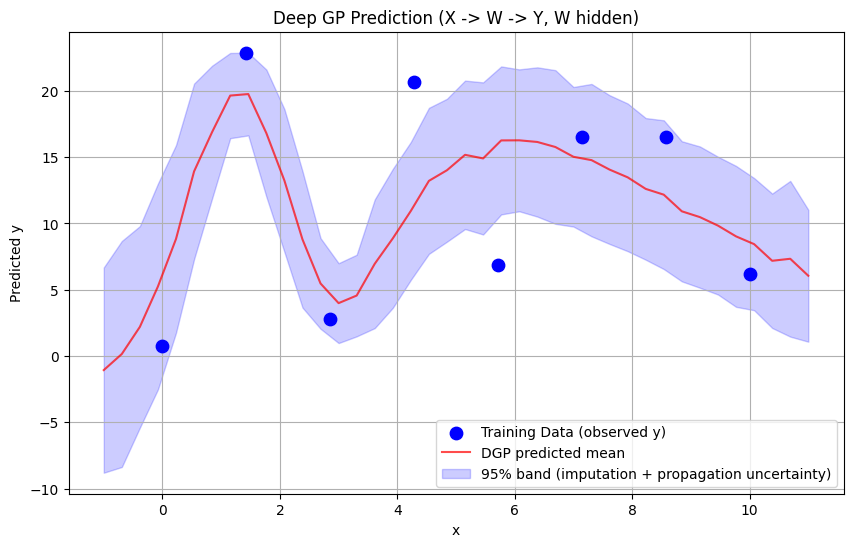

In [172]:
plot_dgp_funnel(x_train, y_train, w_final, hypers[0], hypers[1], hypers[2], hypers[3], nugget=0.05)